In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

NOTEBOOK_DIR = Path.cwd()

if not (NOTEBOOK_DIR / "load.py").exists():
    NOTEBOOK_DIR = Path("cafe-revenue-regression/notebooks")

sys.path.insert(0, str(NOTEBOOK_DIR.resolve()))

from load import load_all

result = load_all()

if isinstance(result, dict):
    train = result["train"]
    stores = result["stores"]
    weather = result["weather"]
    holidays = result["holidays"]
else:
    train, stores, weather, holidays = result

datasets = {
    "train": train,
    "stores": stores,
    "weather": weather,
    "holidays": holidays
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

Đã tìm thấy dữ liệu: C:\Users\USER\Downloads\ML-Kaggle-Project-main\cafe-revenue-regression\data\raw
train: (26632, 4)
stores: (45, 8)
weather: (1593, 4)
holidays: (55, 3)


,dataset,column,missing_count,missing_percent
8,stores,area_m2,2,4.44
15,weather,rain_mm,16,1.00


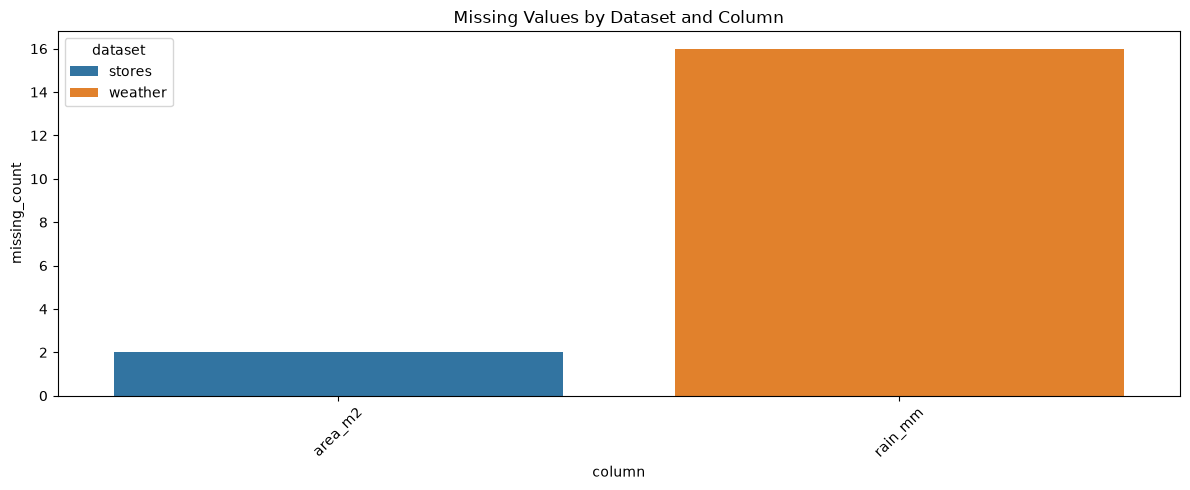

In [2]:
missing_report = []

for name, df in datasets.items():
    for col in df.columns:
        missing_count = int(df[col].isna().sum())
        missing_percent = missing_count / len(df) * 100 if len(df) else 0

        missing_report.append({
            "dataset": name,
            "column": col,
            "missing_count": missing_count,
            "missing_percent": round(missing_percent, 2)
        })

missing_df = pd.DataFrame(missing_report)
display(missing_df[missing_df["missing_count"] > 0])

plt.figure(figsize=(12, 5))
sns.barplot(
    data=missing_df[missing_df["missing_count"] > 0],
    x="column",
    y="missing_count",
    hue="dataset"
)
plt.title("Missing Values by Dataset and Column")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [3]:
duplicate_report = []

for name, df in datasets.items():
    duplicate_report.append({
        "dataset": name,
        "duplicate_rows": int(df.duplicated().sum())
    })

display(pd.DataFrame(duplicate_report))

if {"date", "store_id"}.issubset(train.columns):
    duplicate_keys = train[
        train.duplicated(
            subset=["date", "store_id"],
            keep=False
        )
    ].sort_values(["date", "store_id"])

    print("Số dòng thuộc nhóm trùng date + store_id:",
          len(duplicate_keys))
    display(duplicate_keys.head(20))

,dataset,duplicate_rows
0,train,132
1,stores,0
2,weather,0
3,holidays,0


Số dòng thuộc nhóm trùng date + store_id: 264


,date,store_id,is_promo,revenue
368,2024-01-11,S39,0,15.80
369,2024-01-11,S39,0,15.80
406,2024-01-13,S04,0,17.93
407,2024-01-13,S04,0,17.93
832,2024-01-25,S34,0,17.92
833,2024-01-25,S34,0,17.92
863,2024-01-26,S30,0,16.93
864,2024-01-26,S30,0,16.93
964,2024-01-29,S29,0,26.63
965,2024-01-29,S29,0,26.63


In [4]:
train["revenue"] = pd.to_numeric(
    train["revenue"], errors="coerce"
)

revenue = train["revenue"].dropna()

Q1 = revenue.quantile(0.25)
Q3 = revenue.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (train["revenue"] < lower_bound) |
    (train["revenue"] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Ngưỡng dưới:", lower_bound)
print("Ngưỡng trên:", upper_bound)
print("Số ngoại lệ theo IQR:", int(outlier_mask.sum()))
print("Doanh thu âm:", int((train["revenue"] < 0).sum()))
print("Doanh thu bằng 0:", int((train["revenue"] == 0).sum()))
print("Doanh thu lớn nhất:", train["revenue"].max())

display(
    train.loc[outlier_mask]
    .sort_values("revenue", ascending=False)
    .head(20)
)

Q1: 12.43
Q3: 24.13
IQR: 11.7
Ngưỡng dưới: -5.119999999999997
Ngưỡng trên: 41.67999999999999
Số ngoại lệ theo IQR: 422
Doanh thu âm: 0
Doanh thu bằng 0: 0
Doanh thu lớn nhất: 53600.0


,date,store_id,is_promo,revenue
2139,2024-03-07,S12,1,53600.0
2071,2024-03-05,S12,1,51990.0
2173,2024-03-08,S12,1,45130.0
2880,2024-03-29,S12,1,44280.0
2105,2024-03-06,S12,0,38120.0
2813,2024-03-27,S12,0,35780.0
2373,2024-03-14,S12,0,32380.0
2273,2024-03-11,S12,0,32190.0
2610,2024-03-21,S12,0,32110.0
2579,2024-03-20,S12,0,31670.0


In [5]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"DATASET: {name}")
    print(df.dtypes)

    if "date" in df.columns:
        parsed_dates = pd.to_datetime(
            df["date"], errors="coerce", dayfirst=True
        )

        invalid_count = int(
            (df["date"].notna() & parsed_dates.isna()).sum()
        )

        print("Ngày không hợp lệ:", invalid_count)
        print("Ngày nhỏ nhất:", parsed_dates.min())
        print("Ngày lớn nhất:", parsed_dates.max())


DATASET: train
date        datetime64[ns]
store_id               str
is_promo             int64
revenue            float64
dtype: object
Ngày không hợp lệ: 0
Ngày nhỏ nhất: 2024-01-01 00:00:00
Ngày lớn nhất: 2025-12-31 00:00:00

DATASET: stores
store_id           str
city               str
district           str
store_type         str
area_m2        float64
seats            int64
has_parking      int64
open_date          str
dtype: object

DATASET: weather
date       datetime64[ns]
city                  str
temp_c            float64
rain_mm           float64
dtype: object
Ngày không hợp lệ: 0
Ngày nhỏ nhất: 2024-01-01 00:00:00
Ngày lớn nhất: 2026-03-31 00:00:00

DATASET: holidays
date            datetime64[ns]
holiday_name               str
type                       str
dtype: object
Ngày không hợp lệ: 0
Ngày nhỏ nhất: 2024-01-01 00:00:00
Ngày lớn nhất: 2026-03-08 00:00:00


In [6]:
print("KIỂM TRA STORE_ID")

if "store_id" in train.columns and "store_id" in stores.columns:
    train_store_ids = set(train["store_id"].dropna().unique())
    known_store_ids = set(stores["store_id"].dropna().unique())

    unknown_ids = train_store_ids - known_store_ids

    print("Số cửa hàng trong train:", len(train_store_ids))
    print("Số cửa hàng trong stores:", len(known_store_ids))
    print("Store ID không có trong stores:", sorted(unknown_ids))

print("\nKIỂM TRA DIỆN TÍCH")

if "area_m2" in stores.columns:
    area = pd.to_numeric(stores["area_m2"], errors="coerce")
    print("Diện tích thiếu:", int(area.isna().sum()))
    print("Diện tích âm:", int((area < 0).sum()))

print("\nKIỂM TRA LƯỢNG MƯA")

if "rain_mm" in weather.columns:
    rain = pd.to_numeric(weather["rain_mm"], errors="coerce")
    print("Lượng mưa thiếu:", int(rain.isna().sum()))
    print("Lượng mưa âm:", int((rain < 0).sum()))

KIỂM TRA STORE_ID
Số cửa hàng trong train: 45
Số cửa hàng trong stores: 45
Store ID không có trong stores: []

KIỂM TRA DIỆN TÍCH
Diện tích thiếu: 2
Diện tích âm: 0

KIỂM TRA LƯỢNG MƯA
Lượng mưa thiếu: 16
Lượng mưa âm: 0


In [7]:
OUTPUT_DIR = NOTEBOOK_DIR.resolve().parent / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

missing_df.to_csv(
    OUTPUT_DIR / "missing_values_report.csv",
    index=False,
    encoding="utf-8-sig"
)

duplicate_df = pd.DataFrame(duplicate_report)
duplicate_df.to_csv(
    OUTPUT_DIR / "duplicate_report.csv",
    index=False,
    encoding="utf-8-sig"
)

summary = {
    "train_rows": len(train),
    "stores_rows": len(stores),
    "weather_rows": len(weather),
    "holidays_rows": len(holidays),
    "train_missing_cells": int(train.isna().sum().sum()),
    "train_duplicate_rows": int(train.duplicated().sum()),
    "duplicate_date_store_id": int(
        train.duplicated(["date", "store_id"]).sum()
    ),
    "revenue_outliers_iqr": int(outlier_mask.sum()),
    "negative_revenue": int((train["revenue"] < 0).sum()),
    "zero_revenue": int((train["revenue"] == 0).sum())
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["metric", "value"]
)

summary_df.to_csv(
    OUTPUT_DIR / "data_quality_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

display(summary_df)
print("Đã lưu các báo cáo tại:", OUTPUT_DIR)

,metric,value
0,train_rows,26632
1,stores_rows,45
2,weather_rows,1593
3,holidays_rows,55
4,train_missing_cells,0
5,train_duplicate_rows,132
6,duplicate_date_store_id,132
7,revenue_outliers_iqr,422
8,negative_revenue,0
9,zero_revenue,0


Đã lưu các báo cáo tại: C:\Users\USER\Downloads\ML-Kaggle-Project-main\cafe-revenue-regression\reports
